# Auditoria das fontes de dados

Visualização de `reports/auditoria_fontes.json`, gerado por `python -m src.auditoria` a partir das fontes baixadas em `data/raw/` (ver `docs/02_dados.md`). O JSON contém só contagens e medidas; nenhum texto das fontes aparece aqui.

Termos usados:

- **Chave de comparação**: texto após NFKC, `casefold` e espaços colapsados (`src.auditoria.chave_comparacao`). Duas linhas com a mesma chave são tratadas como o mesmo texto.
- **Duplicatas**: linhas que repetem o texto (exatas) ou a chave de outra linha da mesma fonte.
- **Rótulos divergentes**: chaves que aparecem com rótulos diferentes dentro da mesma fonte.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.patches import Patch

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
auditoria = json.loads((RAIZ / "reports" / "auditoria_fontes.json").read_text(encoding="utf-8"))
fontes = auditoria["fontes"]

AZUL, LARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA_SECUNDARIA, SUPERFICIE = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.facecolor": SUPERFICIE,
        "axes.facecolor": SUPERFICIE,
        "axes.edgecolor": TINTA_SECUNDARIA,
        "axes.labelcolor": TINTA,
        "text.color": TINTA,
        "xtick.color": TINTA_SECUNDARIA,
        "ytick.color": TINTA_SECUNDARIA,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e4e3df",
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
    }
)


def formatar(numero, casas=0):
    texto = f"{numero:,.{casas}f}"
    return texto.replace(",", "_").replace(".", ",").replace("_", ".")


NOMES = {
    "ai-safety-brazil/prompt-injection-br-synthetic": "ai-safety injeção",
    "ai-safety-brazil/jailbreak-br-synthetic": "ai-safety jailbreak",
    "Lakera/gandalf_ignore_instructions": "Gandalf",
    "TrustAIRLab/in-the-wild-jailbreak-prompts": "TrustAIRLab",
    "Lakera/mosscap_prompt_injection": "Mosscap",
    "microsoft/llmail-inject-challenge": "LLMail",
    "deepset/prompt-injections": "deepset",
    "leolee99/NotInject": "NotInject",
    "OpenAssistant/oasst2": "oasst2",
    "allenai/WildChat-1M": "WildChat",
}

## 1. Resumo por fonte

Comprimentos em caracteres. A coluna "> 4.096" conta textos acima do limite de entrada da especificação (seção 4.1), que seriam inválidos para o detector.

In [2]:
resumo = pd.DataFrame(
    {
        NOMES[fonte]: {
            "linhas": dados["linhas"],
            "vazios": dados["vazios"],
            "duplicatas exatas": dados["duplicatas_exatas"],
            "duplicatas pela chave": dados["duplicatas_chave"],
            "rótulos divergentes": dados["chaves_com_rotulos_divergentes"],
            "p50": dados["comprimento"]["p50"],
            "p95": dados["comprimento"]["p95"],
            "máximo": dados["comprimento"]["maximo"],
            "> 4.096": dados["comprimento"]["acima_do_limite"],
        }
        for fonte, dados in fontes.items()
    }
).T
resumo

,linhas,vazios,duplicatas exatas,duplicatas pela chave,rótulos divergentes,p50,p95,máximo,> 4.096
ai-safety injeção,10000,0,0,0,0,394,638,1156,0
ai-safety jailbreak,10000,0,0,0,0,368,684,1256,0
Gandalf,1000,0,0,1,0,61,163,516,0
TrustAIRLab,21527,0,2980,6463,43,833,5249,70972,1838
Mosscap,278945,29,57895,66432,0,56,410,27027,1518
LLMail,37506,0,43,929,85,548,3689,32563,1472
deepset,662,0,0,0,0,65,339,4545,1
NotInject,339,0,0,0,0,90,159,233,0
oasst2,49856,0,769,862,0,71,356,9843,40
WildChat,1960074,17047,236064,255127,0,84,3857,597942,71913


## 2. Duplicatas

Fração das linhas de cada fonte cuja chave já apareceu em outra linha da mesma fonte. Na construção do dataset, duplicatas ficam no mesmo grupo para não vazarem entre partições.

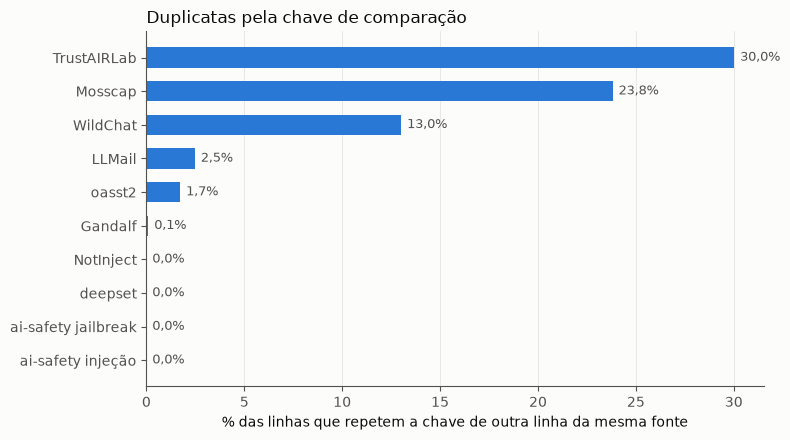

In [3]:
fracao = (resumo["duplicatas pela chave"] / resumo["linhas"] * 100).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(fracao.index, fracao.to_numpy(), color=AZUL, height=0.6)
for posicao, valor in enumerate(fracao):
    rotulo = f"{formatar(valor, 1)}%"
    ax.text(valor + 0.3, posicao, rotulo, va="center", fontsize=9, color=TINTA_SECUNDARIA)
ax.set_xlabel("% das linhas que repetem a chave de outra linha da mesma fonte")
ax.set_title("Duplicatas pela chave de comparação", loc="left")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

## 3. Comprimento dos textos

Distribuição por faixas de caracteres; em laranja, as faixas acima do limite de 4.096. Cada painel mostra a porcentagem das linhas da própria fonte, para comparar formas entre fontes de tamanhos muito diferentes.

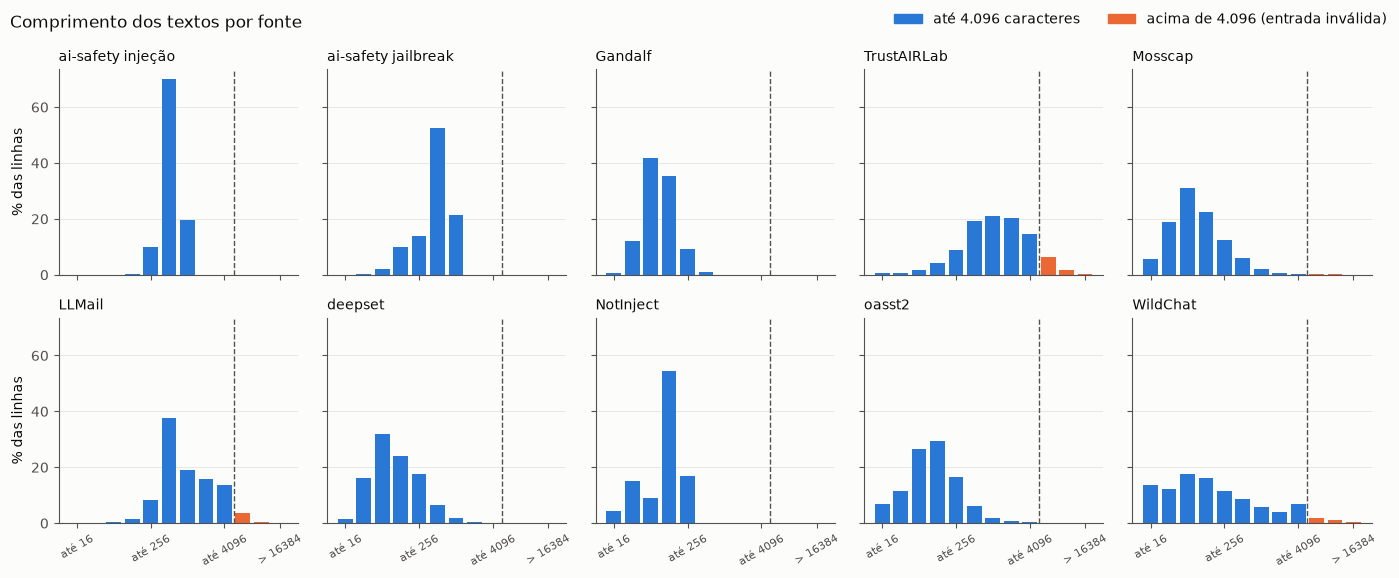

In [4]:
limites = auditoria["limites_faixas"]
indice_limite = limites.index(auditoria["limite_caracteres"])
rotulos_faixas = [f"até {limite}" for limite in limites] + [f"> {limites[-1]}"]
marcas = [0, 4, indice_limite, len(limites)]

fig, eixos = plt.subplots(2, 5, figsize=(14, 5.8), sharex=True, sharey=True)
for ax, (fonte, dados) in zip(eixos.flat, fontes.items(), strict=True):
    faixas = np.array(dados["comprimento"]["faixas"])
    proporcao = faixas / faixas.sum() * 100
    cores = [AZUL if i <= indice_limite else LARANJA for i in range(len(faixas))]
    ax.bar(range(len(faixas)), proporcao, color=cores, width=0.8)
    ax.axvline(indice_limite + 0.5, color=TINTA_SECUNDARIA, linestyle="--", linewidth=1)
    ax.set_title(NOMES[fonte], fontsize=10, loc="left")
    ax.grid(axis="x", visible=False)
for ax in eixos[1]:
    ax.set_xticks(marcas, [rotulos_faixas[i] for i in marcas], fontsize=8, rotation=30)
for ax in eixos[:, 0]:
    ax.set_ylabel("% das linhas")
fig.legend(
    handles=[
        Patch(color=AZUL, label="até 4.096 caracteres"),
        Patch(color=LARANJA, label="acima de 4.096 (entrada inválida)"),
    ],
    loc="upper right",
    frameon=False,
    ncols=2,
)
fig.suptitle("Comprimento dos textos por fonte", x=0.01, ha="left")
fig.tight_layout()
plt.show()

## 4. Sobreposição entre fontes

Número de chaves distintas presentes nas duas fontes (escala log). A matriz é simétrica, então só a metade inferior é mostrada. Sobreposição com textos longos sugere o mesmo ataque catalogado em duas fontes; com textos muito curtos, coincidências como saudações. A tabela abaixo do mapa mostra a mediana do comprimento das chaves em comum.

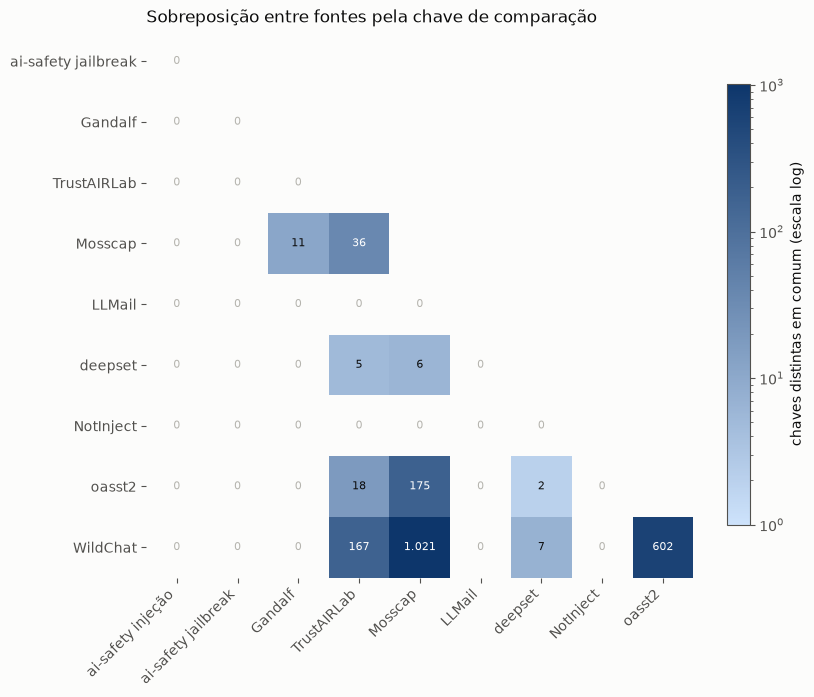

In [5]:
nomes = [NOMES[fonte] for fonte in fontes]
matriz = np.array(
    [[auditoria["sobreposicao"][a][b]["textos"] for b in fontes] for a in fontes], dtype=float
)
inferior = matriz[1:, :-1]
acima_da_diagonal = np.triu(np.ones_like(inferior, dtype=bool), k=1)
positivos = np.ma.masked_where(acima_da_diagonal | (inferior == 0), inferior)
mapa = LinearSegmentedColormap.from_list("azul", ["#cde2fb", "#0d366b"])
mapa.set_bad(SUPERFICIE)
maximo = inferior[~acima_da_diagonal].max()
limiar_texto_claro = np.sqrt(maximo)

fig, ax = plt.subplots(figsize=(8.5, 7))
imagem = ax.imshow(positivos, cmap=mapa, norm=LogNorm(vmin=1, vmax=maximo))
ax.set_xticks(range(len(nomes) - 1), nomes[:-1], rotation=45, ha="right")
ax.set_yticks(range(len(nomes) - 1), nomes[1:])
ax.grid(False)
ax.spines[:].set_visible(False)
for i in range(len(nomes) - 1):
    for j in range(i + 1):
        valor = inferior[i, j]
        cor = "white" if valor > limiar_texto_claro else (TINTA if valor > 0 else "#b5b4ae")
        ax.text(j, i, formatar(valor), ha="center", va="center", fontsize=8, color=cor)
fig.colorbar(imagem, ax=ax, shrink=0.8, label="chaves distintas em comum (escala log)")
ax.set_title("Sobreposição entre fontes pela chave de comparação", loc="left")
fig.tight_layout()
plt.show()

In [6]:
pares = [
    {
        "fonte A": NOMES[a],
        "fonte B": NOMES[b],
        "textos em comum": comum["textos"],
        "mediana do comprimento": comum["mediana_comprimento"],
    }
    for i, a in enumerate(fontes)
    for j, b in enumerate(fontes)
    if i < j and (comum := auditoria["sobreposicao"][a][b])["textos"] > 0
]
pd.DataFrame(pares).sort_values("textos em comum", ascending=False).reset_index(drop=True)

,fonte A,fonte B,textos em comum,mediana do comprimento
0,Mosscap,WildChat,1021,12
1,oasst2,WildChat,602,9
2,Mosscap,oasst2,175,9
3,TrustAIRLab,WildChat,167,825
4,TrustAIRLab,Mosscap,36,426
5,TrustAIRLab,oasst2,18,16
6,Gandalf,Mosscap,11,32
7,deepset,WildChat,7,28
8,Mosscap,deepset,6,17
9,TrustAIRLab,deepset,5,448


## 5. Rótulos das fontes

Rótulos originais, antes de qualquer mapeamento para a definição do projeto (D1 e D2). Só as fontes que têm rótulo aparecem.

In [7]:
rotulos = {
    NOMES[fonte]: dados["contagens"]["rotulo_fonte"]
    for fonte, dados in fontes.items()
    if "(ausente)" not in dados["contagens"]["rotulo_fonte"]
}
pd.DataFrame(rotulos).fillna(0).astype(int)

,ai-safety injeção,ai-safety jailbreak,TrustAIRLab,LLMail,deepset
0,6000,6000,0,0,399
1,4000,4000,0,0,263
False,0,0,19456,2500,0
True,0,0,2071,21007,0
Unclear,0,0,0,13796,0
benigno,0,0,0,203,0


## 6. Mensagens em português

Idioma informado pela própria fonte: `language_detected` no ai-safety-brazil, `lang` no oasst2 e o idioma de cada mensagem no WildChat. As demais fontes não informam idioma por linha e são declaradas em inglês, ou sem idioma no caso do deepset.

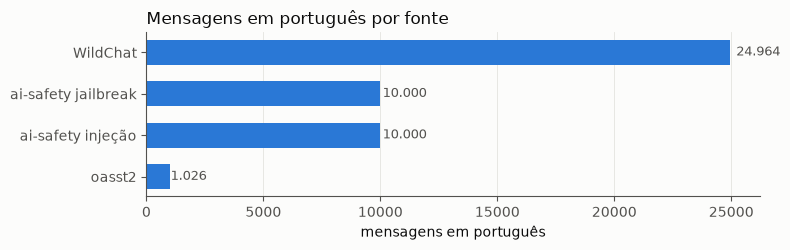

In [8]:
CODIGOS_PORTUGUES = {"pt", "pt-BR", "Portuguese"}
portugues = pd.Series(
    {
        NOMES[fonte]: sum(
            n
            for idioma, n in dados["contagens"]["idioma_fonte"].items()
            if idioma in CODIGOS_PORTUGUES
        )
        for fonte, dados in fontes.items()
    }
)
portugues = portugues[portugues > 0].sort_values()

fig, ax = plt.subplots(figsize=(8, 2.6))
ax.barh(portugues.index, portugues.to_numpy(), color=AZUL, height=0.6)
for posicao, valor in enumerate(portugues):
    ax.text(valor * 1.01, posicao, formatar(valor), va="center", fontsize=9, color=TINTA_SECUNDARIA)
ax.set_xlabel("mensagens em português")
ax.set_title("Mensagens em português por fonte", loc="left")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()